# Exploratory Data Analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statistics import NormalDist

## Setup

In [ ]:
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

LEVELS = [1, 2, 3, 4]
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}
LEVEL_NAMES = {1: "1 low", 2: "2 moderate", 3: "3 considerable", 4: "4 high"}
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": GREY, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 11,
})

data = pd.read_csv("data/final.csv", parse_dates=["date"])
data = data.sort_values(["region", "date"]).reset_index(drop=True)

NUM = {
    "air_temp_mean": "Mean air temp (°C)", "air_temp_min": "Min air temp (°C)",
    "air_temp_max": "Max air temp (°C)", "wind_speed_mean": "Mean wind (m/s)",
    "wind_gust_max": "Max gust (m/s)", "rel_humidity_mean": "Rel. humidity (%)",
    "pressure_mean": "Station pressure (hPa)", "sunshine_sum": "Sunshine (h)",
    "snow_depth_cm": "Snow depth (cm)", "precip_sum_mm": "Precipitation (mm)",
}

### Feature engineering

| Column | Definition | Used in |
|---|---|---|
| `month` | calendar month of `date` | 3.1, 4.1, 4.2 |
| `spring` | `True` for March–May (wet-snow period) | 4.2 |
| `prev_danger` | danger level of the **previous day** in the same region and season (NaN on the first day of a season) | 3.1, 4.5 |
| `snow_depth_clean` | snow depth after a causal 3-day rolling median (removes one-day sensor spikes, uses only past values); helper for the snow changes | 4.5 |
| `precip_3d`, `precip_7d` | precipitation summed over the last 3 / 7 days | 4.5 |
| `log_precip_3d` | $\log(1 + \text{precip\_3d})$, log transformation against the strong right skew (DEA-06) | 4.5 |
| `snow_change_3d`, `snow_change_14d` | change of `snow_depth_clean` over the last 3 / 14 days (fresh snow vs. settling) | 4.5 |
| `temp_mean_14d` | mean air temperature over the last 14 days (long cold spells) | 4.5 |
| `pressure_anom` | pressure minus the station's mean pressure (removes the elevation effect, 2.5) | 4.5 |
| `snow_depth_z` | snow depth standardised per station, $(x - \bar{x}_{station}) / s_{station}$ (DEA-06 standardization) | 4.5 |

- All rolling/lag features are computed per **(region, season)**, so no window reaches across the summer gap between two winters.
- Features that did **not** improve on the raw variables and were therefore dropped: 3-day max gust, 3-day mean temperature, daily temperature range, wind direction as sin/cos, day of season.

In [ ]:
data["month"] = data["date"].dt.month
data["spring"] = data["month"].isin([3, 4, 5])
grp = data.groupby(["region", "season"])            # per season: no window reaches over the summer gap
data["prev_danger"] = grp["danger_max"].shift(1)

# snow depth
data["snow_depth_clean"] = grp["snow_depth_cm"].transform(lambda x: x.rolling(3, min_periods=1).median())
data["snow_change_3d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(3)
data["snow_change_14d"] = data.groupby(["region", "season"])["snow_depth_clean"].diff(14)

# precipitation accumulated over several days
data["precip_3d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(3, min_periods=1).sum())
data["precip_7d"] = grp["precip_sum_mm"].transform(lambda x: x.rolling(7, min_periods=1).sum())
data["log_precip_3d"] = np.log1p(data["precip_3d"])

# long-term temp
data["temp_mean_14d"] = grp["air_temp_mean"].transform(lambda x: x.rolling(14, min_periods=1).mean())

# per-station normalisation
st = data.groupby("station_name")
data["pressure_anom"] = data["pressure_mean"] - st["pressure_mean"].transform("mean")
data["snow_depth_z"] = (data["snow_depth_cm"] - st["snow_depth_cm"].transform("mean")) / st["snow_depth_cm"].transform("std")

ENGINEERED = ["month", "spring", "prev_danger", "snow_depth_clean", "snow_change_3d",
              "snow_change_14d", "precip_3d", "precip_7d", "log_precip_3d", "temp_mean_14d",
              "pressure_anom", "snow_depth_z"]

# numerical engineered features
ENG_NUM = {"log_precip_3d": "precip_sum_mm", "precip_3d": "precip_sum_mm", "precip_7d": "precip_sum_mm",
           "snow_change_14d": "snow_depth_cm", "snow_change_3d": "snow_depth_cm", "temp_mean_14d": "air_temp_mean",
           "snow_depth_z": "snow_depth_cm", "pressure_anom": "pressure_mean"}

print("missing values:", data[ENGINEERED].isna().sum()[lambda x: x > 0].to_dict(), "(first days of each season)")
data[["date", "region", "danger_max"] + ENGINEERED].head()

## 1. Univariate non-graphical EDA

### 1.1 Spread

In [55]:
def sample_var(x):
    x = x.dropna()
    return ((x - x.mean()) ** 2).sum() / (len(x) - 1)

spread = pd.DataFrame({
    "min": data[list(NUM)].min(), "max": data[list(NUM)].max(),
    "range": data[list(NUM)].max() - data[list(NUM)].min(),
    "variance (n-1)": {c: sample_var(data[c]) for c in NUM},
    "std": {c: np.sqrt(sample_var(data[c])) for c in NUM},
    "Q1": data[list(NUM)].quantile(0.25), "Q3": data[list(NUM)].quantile(0.75),
})
spread["IQR"] = spread["Q3"] - spread["Q1"]
spread["std / IQR"] = spread["std"] / spread["IQR"]
spread

,min,max,range,variance (n-1),std,Q1,Q3,IQR,std / IQR
air_temp_mean,-20.80,15.12,35.91,25.08,5.01,-6.03,0.73,6.76,0.74
air_temp_min,-22.86,13.10,35.96,25.62,5.06,-8.87,-1.98,6.89,0.73
air_temp_max,-18.22,21.41,39.63,30.38,5.51,-2.46,4.77,7.22,0.76
wind_speed_mean,0.39,18.28,17.89,3.78,1.95,1.63,3.74,2.11,0.92
wind_gust_max,2.57,39.54,36.97,26.89,5.19,7.41,13.99,6.58,0.79
rel_humidity_mean,9.67,99.52,89.85,294.00,17.15,57.50,81.89,24.39,0.70
pressure_mean,680.71,866.34,185.63,1522.84,39.02,779.25,820.35,41.10,0.95
sunshine_sum,0.00,13.53,13.53,9.67,3.11,0.61,5.82,5.21,0.60
snow_depth_cm,0.00,318.74,318.74,4578.55,67.66,45.60,147.12,101.51,0.67
precip_sum_mm,0.00,70.10,70.10,21.10,4.59,0.00,1.59,1.59,2.89


In [56]:
rows = []
for c in NUM:
    x = data[c]
    lo, hi = x.quantile([0.005, 0.995]) # 0,5 % and 99,5 % quantile
    x_cut = x[x.between(lo, hi)]
    rows.append({"variable": c,
                 "range: all": x.max() - x.min(), "range: w/o 1%": x_cut.max() - x_cut.min(),
                 "std: all": x.std(), "std: w/o 1%": x_cut.std(),
                 "IQR: all": x.quantile(.75) - x.quantile(.25), "IQR: w/o 1%": x_cut.quantile(.75) - x_cut.quantile(.25),
                 "median: all": x.median(), "median: w/o 1%": x_cut.median()})
robust = pd.DataFrame(rows).set_index("variable")
for m in ["range", "std", "IQR", "median"]:
    robust[f"{m} change %"] = (robust[f"{m}: w/o 1%"] / robust[f"{m}: all"] - 1) * 100
robust[[c for c in robust if "change" in c]].round(1)

,range change %,std change %,IQR change %,median change %
variable,,,,
air_temp_mean,-29.4,-3.6,-1.3,0.0
air_temp_min,-29.0,-3.6,-1.1,0.0
air_temp_max,-28.4,-3.8,-1.3,0.0
wind_speed_mean,-43.0,-6.8,-1.4,0.0
wind_gust_max,-29.8,-4.6,-0.9,0.0
rel_humidity_mean,-16.0,-2.5,-1.0,0.0
pressure_mean,-9.4,-2.2,-0.9,0.0
sunshine_sum,-12.2,-1.9,-0.7,-1.1
snow_depth_cm,-12.2,-1.9,-0.8,-0.4


* Removing just 1% of the observations shrinks the **range** by 10–60%, and the **std** of precipitation drops by 18%. The **IQR** changes by at most 3.2%
* Precipitation has an IQR of only ~1.6 mm but a range of 70 mm, and its std is about three times its IQR ->  skewed with a long tail.

**Consequences:**
- Because of the skeweness we are going to use tree-based models.

### 1.3 Outliers

In [ ]:
def outlier_counts(x):
    z = (x - x.mean()) / x.std()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    mad = (x - x.median()).abs().median()
    return {"z-score |z|>3": (z.abs() > 3).sum(),
            "IQR fences": ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum(),
            "MAD > 3": ((x - x.median()).abs() / (1.4826 * mad) > 3).sum() if mad > 0 else np.nan,
            "MAD": mad}

out = pd.DataFrame({c: outlier_counts(data[c]) for c in NUM}).T
out["IQR fences %"] = out["IQR fences"] / len(data) * 100
out.sort_values("IQR fences", ascending=False)

* The rules disagree strongly for skewed variables. For precipitation, the IQR rule flags 14.5% of all days because Q1 = 0, and since MAD ≈ 0.01 mm (about half the days are dry) the MAD rule flags almost half of the data, which is clearly useless.
* For pressure, the IQR rule flags ~11% of the rows, which are simply the days of the highest station (Pitztaler Gletscher), not unusual weather.
* The flagged precipitation days have clearly **higher** danger levels than the rest (65% level 3–4 vs. 30%), so they are the most informative observations, not errors.
* For temperatures, very few points (< 1%) are flagged by any rule.

**Consequences:**
-> we do **not** remove statistical outliers.

## 2. Univariate graphical EDA
### 2.1 Bar charts (categorical variables)

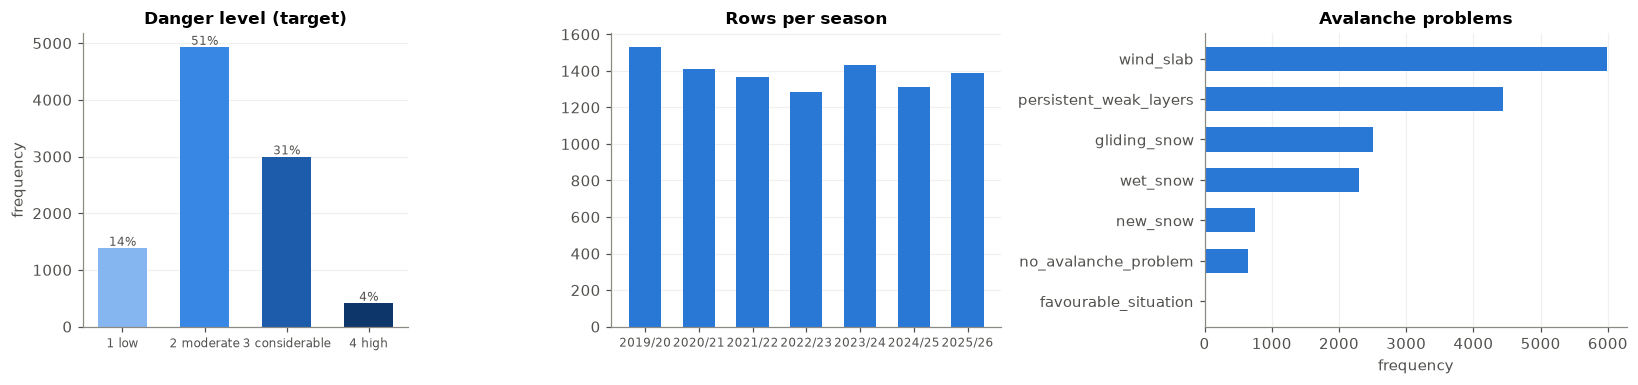

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1.2, 1.3]})

t = tab_target["frequency"]
axes[0].bar([LEVEL_NAMES[l] for l in t.index], t.values, color=[LEVEL_COLORS[l] for l in t.index], width=0.6)
for i, v in enumerate(t.values):
    axes[0].text(i, v + 40, f"{v / t.sum():.0%}", ha="center", fontsize=8, color="#52514e")
axes[0].set_title("Danger level (target)"); axes[0].set_ylabel("frequency")
axes[0].tick_params(axis="x", labelsize=8)

season_mean = data.groupby("season").size()
axes[1].bar(season_mean.index, season_mean.values, color=BLUE, width=0.6)
axes[1].set_title("Rows per season"); axes[1].tick_params(axis="x", labelsize=8)

prob = data["problems"].str.split(";").explode().value_counts()
axes[2].barh(prob.index, prob.values, color=BLUE, height=0.6)
axes[2].invert_yaxis(); axes[2].set_title("Avalanche problems"); axes[2].set_xlabel("frequency")
for ax in axes[:2]:
    ax.grid(axis="x", visible=False)
axes[2].grid(axis="y", visible=False)
plt.tight_layout()

**Consequences:** the model will be trained on an imbalanced target. Always predicting level 2 already gives ~51% accuracy.

### 2.2 Histograms: bin width matters


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, col in enumerate(["snow_depth_cm", "pressure_mean"]):
    for ax, bins in zip(axes[row], [6, 30, 150]):
        ax.hist(data[col], bins=bins, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.set_title(f"{NUM[col]}: {bins} bins", fontsize=9)
        ax.grid(axis="x", visible=False)
plt.tight_layout()

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.6))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    ax.hist(data[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.axvline(data[col].mean(), color=ORANGE, lw=1.5, label="mean")
    ax.axvline(data[col].median(), color="black", lw=1.2, ls="--", label="median")
    ax.set_title(label, fontsize=9); ax.grid(axis="x", visible=False)
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("Histograms of all numerical variables (40 bins), mean vs. median", fontweight="bold")
plt.tight_layout()

- the mean lies to the right of the median for precipitation, wind, gusts and snow depth (right skew),
- and to the left for humidity and pressure (left skew)

### 2.4 Boxplots

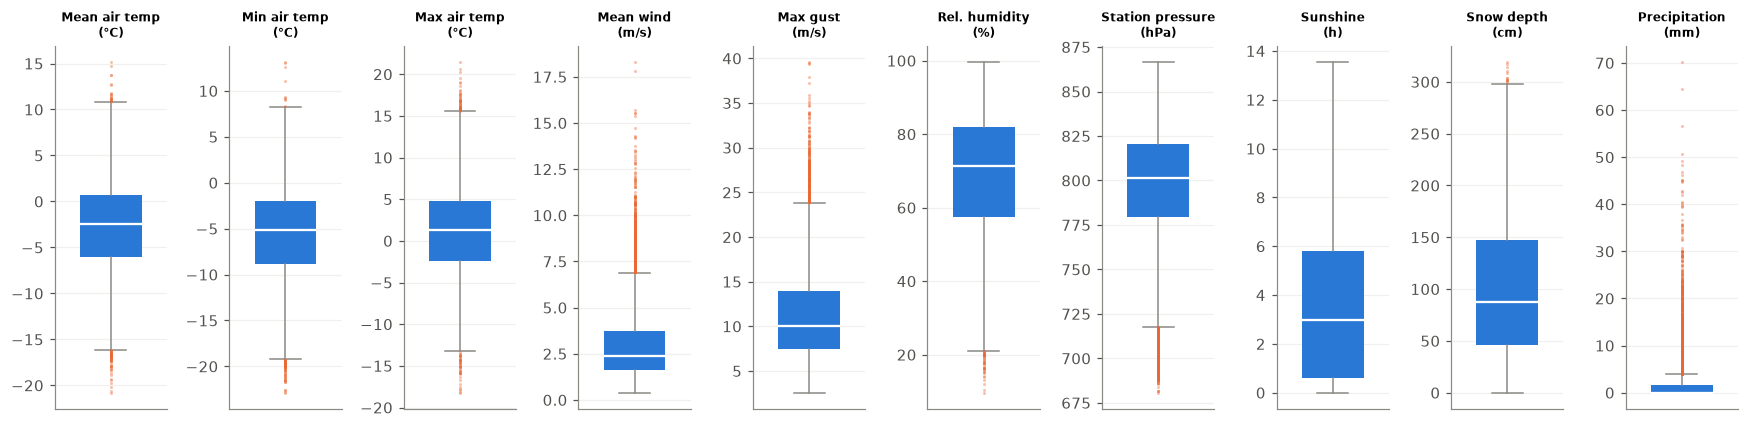

In [51]:
fig, axes = plt.subplots(1, 10, figsize=(16, 4))
for ax, (col, label) in zip(axes, NUM.items()):
    ax.boxplot(data[col].dropna(), widths=0.55, patch_artist=True,
               boxprops={"facecolor": BLUE, "edgecolor": "none"},
               medianprops={"color": "white", "linewidth": 1.5},
               whiskerprops={"color": GREY}, capprops={"color": GREY},
               flierprops={"marker": "o", "markersize": 2, "markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.4})
    ax.set_title(label.replace(" (", "\n("), fontsize=8); ax.set_xticks([])
plt.tight_layout()

- many points beyond the whiskers for precipitation, wind speed and gusts (long right tails),
- many low outliers for humidity and pressure

### 2.5 Violin plots
A violin plot shows the (mirrored) density, so it adds the shape that the boxplot hides. We compare snow depth and pressure across the 9 stations, because the multimodal histograms suggested a station effect.

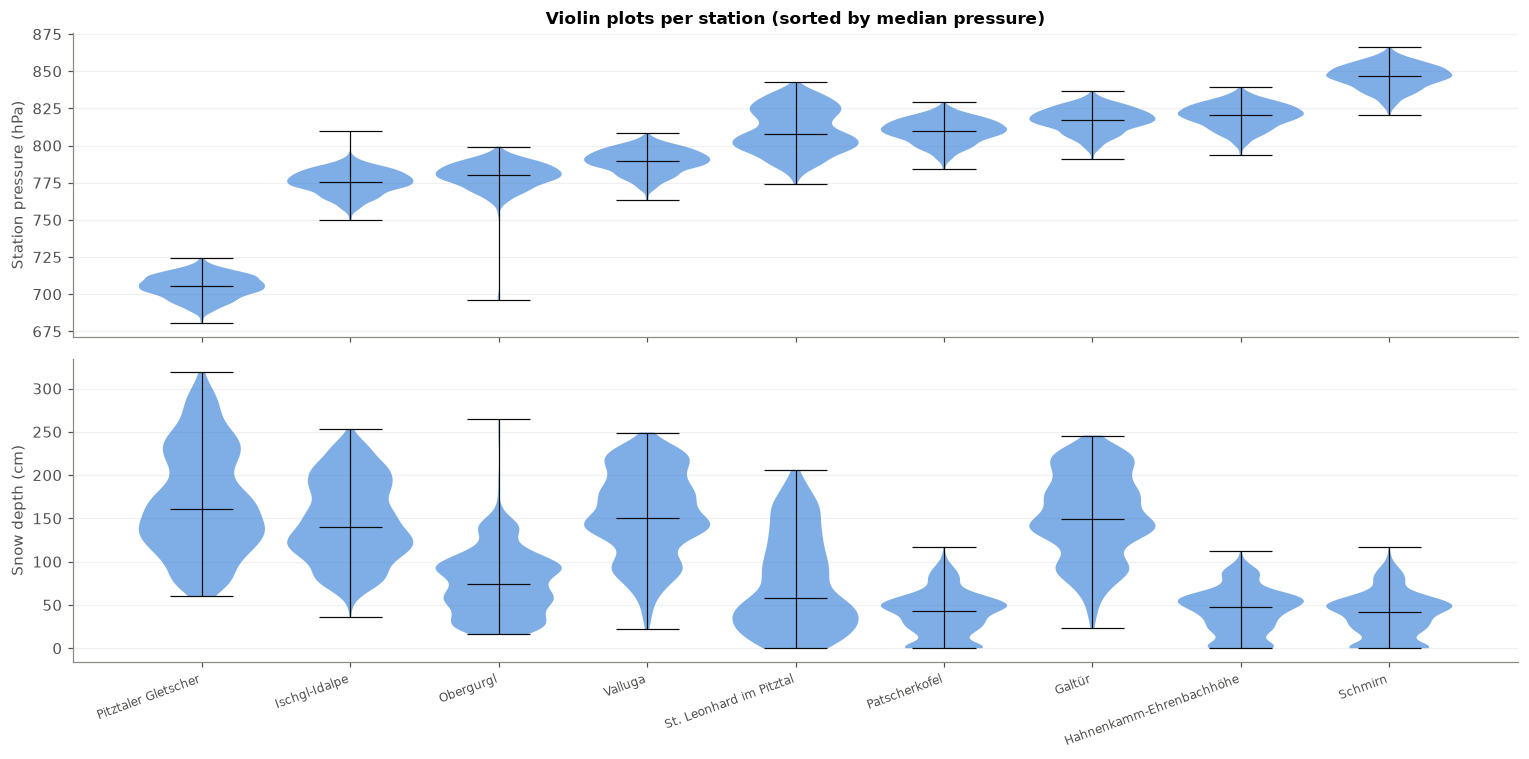

In [52]:
stations = data.groupby("station_name")["pressure_mean"].median().sort_values().index
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, col in zip(axes, ["pressure_mean", "snow_depth_cm"]):
    groups = [data.loc[data["station_name"] == s, col].dropna() for s in stations]
    vp = ax.violinplot(groups, showmedians=True, widths=0.85)
    for b in vp["bodies"]:
        b.set_facecolor(BLUE); b.set_edgecolor("none"); b.set_alpha(0.6)
    for k in ["cmedians", "cmins", "cmaxes", "cbars"]:
        vp[k].set_color("#0b0b0b"); vp[k].set_linewidth(0.8)
    ax.set_ylabel(NUM[col]); ax.grid(axis="x", visible=False)
axes[1].set_xticks(range(1, len(stations) + 1), stations, rotation=20, ha="right", fontsize=8)
axes[0].set_title("Violin plots per station (sorted by median pressure)")
plt.tight_layout()

* **Pressure:** each station has its own narrow distribution. The left-skewed pressure distribution is just the mix of these 9 stations.
* **Snow depth:** the stations differ strongly in level and shape. Some distributions are bimodal because of many 0-cm days at the start and end of the season plus a winter peak.


**Consequences:**
- For modelling, we should use pressure (and possibly snow depth) **relative to the station** (for standardization)

### 2.6 Normal Q–Q plots

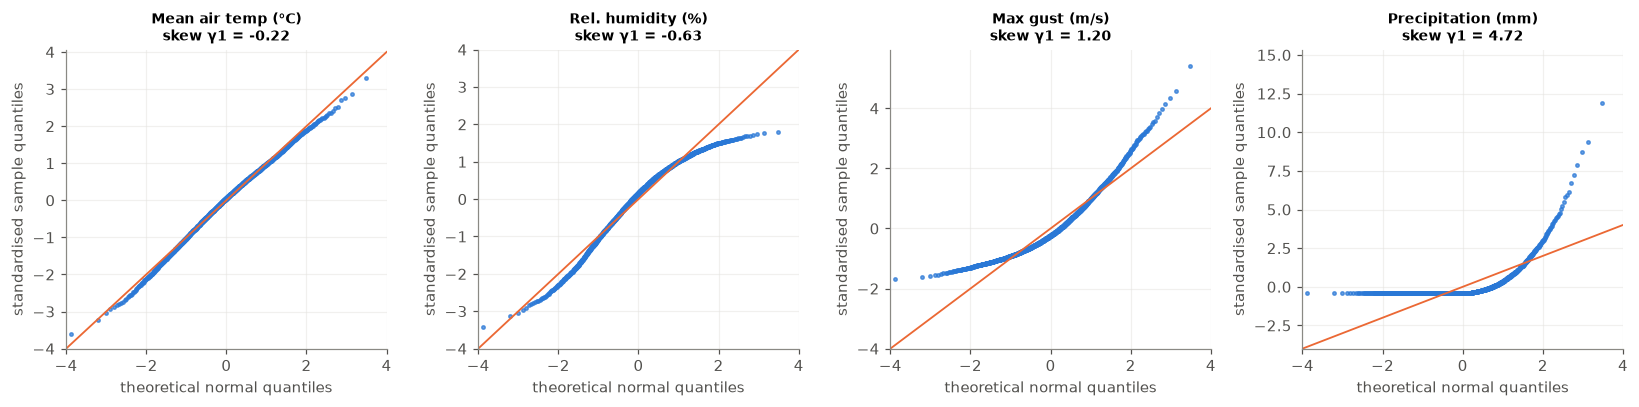

In [53]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, col in zip(axes, ["air_temp_mean", "rel_humidity_mean", "wind_gust_max", "precip_sum_mm"]):
    x = np.sort(data[col].dropna().values)
    n = len(x)
    p = (np.arange(1, n + 1) - 0.5) / n
    theo = np.array([NormalDist().inv_cdf(q) for q in p])
    z = (x - x.mean()) / x.std(ddof=1)
    step = max(1, n // 1500)
    ax.scatter(theo[::step], z[::step], s=5, color=BLUE, alpha=0.7)
    ax.plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, max(4, z.max() + 0.5))
    ax.set_title(f"{NUM[col]}\nskew γ1 = {shape.loc[col, 'skewness γ1']:.2f}", fontsize=9)
    ax.set_xlabel("theoretical normal quantiles"); ax.set_ylabel("standardised sample quantiles")
plt.tight_layout()

* **Mean air temperature:** slight deviations in the tails: approximately normal.
* **Humidity** curves below the line at the left end.
* **Max gust** curves upwards at the right end.
* **Precipitation** is far from normal: a flat segment at the bottom and a steep upward curve at the top.

**Consequences:** methods that assume normally distributed inputs or errors should not be applied to precipitation, wind or sunshine without transformation. Temperatures can be used as they are.

### Summary of the univariate analysis
| Variable group | Shape | Consequence |
|---|---|---|
| Danger level | ordinal, imbalanced (51% level 2, 4% level 4, no level 5) | macro-F1/per-class metrics, majority baseline, class weights |
| Temperatures | ≈ normal, few outliers | use as is |
| Precipitation, wind, gusts, sunshine | right-skewed, heavy tails, many zeros (precip/sun) | log transformation / robust scaling for linear models, keep outliers |
| Humidity | left-skewed, bounded at 100% | robust statistics |
| Pressure, snow depth | multimodal because of different stations | normalise per station / add region feature |

## 3. Multivariate non-graphical EDA

### 3.1 Cross-tabulation
Contingency tables of categorical variables with the danger level. **Row percentages** answer: *how does the danger level distribution differ across the categories?*

In [ ]:
def crosstab_with_pct(row):
    counts = pd.crosstab(data[row], data["danger_max"], margins=True, margins_name="total")
    pct = pd.crosstab(data[row], data["danger_max"], normalize="index") * 100
    return counts, pct

counts, pct = crosstab_with_pct("station_name")
print("counts:"); print(counts.to_string())
print("\nrow percentages:"); pct.round(1)

In [ ]:
for row in ["season", "month", "tendency", "days_before"]:
    _, pct = crosstab_with_pct(row)
    if row == "month":
        pct = pct.reindex([11, 12, 1, 2, 3, 4, 5])
    print(f"--- danger level by {row} (row %)")
    print(pct.round(1).to_string(), "\n")

In [ ]:
# Previous day's level (known before the bulletin) vs. today's level: a cross-tab of two categorical variables
prev = data["prev_danger"]
trans = pd.crosstab(prev.rename("level yesterday"), data["danger_max"].rename("level today"), normalize="index") * 100
print(f"level unchanged from the previous day: {(prev == data['danger_max'])[prev.notna()].mean():.1%}")
trans.round(1)

* **Regions:** 8 of 9 regions have very similar distributions. Kitzbüheler Alpen (station Hahnenkamm, the lowest station) has about twice as many level-1 days and fewer level-3/4 days.
* **Seasons:** the share of level-4 days varies several-fold between winters (e.g. ~1% in 2024/25 vs. ~6.5% in 2025/26). The test season will therefore look different from the training seasons.
* **Months:** level 4 is most frequent in February (9%) and December (6.6%), and almost never occurs from March on (< 1%). In spring level 2 dominates (54–64%).
* **`days_before`:** bulletins published on the morning of the valid day have much higher levels. These are updates in critical situations. `days_before` is only known after publication, so it cannot be a feature.
* **Yesterday's level:** about 79% of days keep the previous day's level.

**Consequences:** region and month/season are useful categorical features. The model must beat a **persistence baseline** (predict yesterday's level, ~79% accuracy), not just the majority class. Train/test must be split **by season**, because neighbouring days are almost identical.

### 3.2 Univariate statistics by category
Summary statistics of each numerical variable **per danger level**. As the lecture recommends, we compare location *and* spread and keep the group sizes in view (level 4 has only 416 rows).

In [ ]:
key = ["precip_sum_mm", "wind_gust_max", "rel_humidity_mean", "sunshine_sum", "snow_depth_cm", "air_temp_mean"]
by_level = data.groupby("danger_max")[key].agg(["median", lambda x: x.quantile(.75) - x.quantile(.25)])
by_level.columns = [f"{c} {'IQR' if s == '<lambda_0>' else s}" for c, s in by_level.columns]
by_level.insert(0, "n", data.groupby("danger_max").size())
by_level.T

In [ ]:
# Mean, std and group size per level for all numerical variables
data.groupby("danger_max")[list(NUM)].agg(["mean", "std"]).T.round(2)

* From level 1 to level 4, the median **precipitation** rises from 0 to ~6 mm, **gusts** from ~9 to ~16 m/s, **humidity** from ~61% to ~84%, **snow depth** from ~69 to ~127 cm, while **sunshine** falls from ~4.4 h to ~0 h and **temperature** falls by ~3 °C.
* The **spread** of precipitation and gusts grows with the level as well (the IQR of precipitation rises from 0 to ~12 mm). High-danger days are more variable, not just shifted. For humidity and sunshine the spread *shrinks* at level 4: high-danger days are almost always humid and overcast.
* The differences between neighbouring levels (especially 2 vs. 3) are small compared to the spread within each level, so no single variable separates the classes.

### 3.3 Covariance and correlation
Sample covariance $s_{XY} = \frac{1}{n-1}\sum (x_i-\bar x)(y_i-\bar y)$ and Pearson correlation $r = \frac{s_{XY}}{s_X s_Y}$, computed from the formulas and checked against pandas.

In [ ]:
def sample_cov(x, y):
    return ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)

x, y = data["precip_sum_mm"], data["danger_max"]
s_xy = sample_cov(x, y)
r = s_xy / (x.std() * y.std())
print(f"cov(precip, danger) = {s_xy:.3f} mm·level   (pandas: {x.cov(y):.3f})")
print(f"r(precip, danger)   = {r:.3f}             (pandas: {x.corr(y):.3f})")

In [ ]:
COLS = list(NUM) + ["danger_max"]
cov = data[COLS].cov()
print("Covariance matrix (units differ, so magnitudes cannot be compared):")
cov.round(1)

In [ ]:
corr = data[COLS].corr()          # Pearson
corr.round(2)

In [ ]:
def strength(r):
    a = abs(r)
    return ("no" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong" if a < 0.7 else "very strong")

target_corr = corr["danger_max"].drop("danger_max").sort_values(key=abs, ascending=False).to_frame("r with danger_max")
target_corr["direction"] = np.where(target_corr["r with danger_max"] > 0, "positive", "negative")
target_corr["description (slide 46)"] = target_corr["r with danger_max"].map(strength) + " linear relationship"
target_corr

In [ ]:
pairs = corr.drop(index="danger_max", columns="danger_max")
pairs = (pairs.where(np.triu(np.ones(pairs.shape, dtype=bool), k=1)).stack()
              .rename("r").reset_index().rename(columns={"level_0": "variable A", "level_1": "variable B"}))
pairs["description"] = pairs["r"].map(strength)
pairs.loc[pairs["r"].abs() >= 0.5].sort_values("r", key=abs, ascending=False)

* The **covariance matrix** is hard to read: pressure and snow depth have huge variances only because of their units/scale. This is why we interpret the **correlation matrix** instead.
* Correlation with the danger level (Pearson, treating the ordinal level as numeric): only **precipitation** reaches a *moderate* linear relationship (r = 0.35). Gusts, humidity, sunshine (negative), wind, snow depth and temperature are *weak*, and pressure shows *no* linear relationship. No variable has a strong linear relationship with the target.
* **Pairs of predictors:** the three temperatures are very strongly correlated with each other (r > 0.85), and so are mean wind and gusts. Sunshine is strongly negatively correlated with humidity. These variables carry largely the same information (redundancy).
* As the lecture warns: r ≈ 0 does not mean independence, a nonlinear relationship can still exist (checked graphically in Section 4). And correlation is not causation: high humidity does not *cause* avalanches, it comes with snowfall.

**Consequences:** for linear models keep only one variable per highly correlated group (e.g. `air_temp_mean`, `wind_gust_max`), otherwise the coefficients are unstable. Because no single feature is strongly related to the target, the model has to combine several weak signals.

---
## 4. Multivariate graphical EDA

### 4.1 Univariate graph per category: grouped boxplots

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2))
for ax, (col, label) in zip(axes.flat, NUM.items()):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY},
                    flierprops={"marker": "o", "markersize": 1.5, "markerfacecolor": GREY, "markeredgecolor": "none", "alpha": 0.4})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(label, fontsize=9); ax.set_xlabel("danger level", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Parallel boxplots: numerical variables by danger level", fontweight="bold")
plt.tight_layout()

* Precipitation, gusts, humidity and snow depth shift **upwards** and sunshine **downwards** with increasing level. The boxes of neighbouring levels overlap a lot, especially 2 and 3, which matches the weak-to-moderate correlations.
* The **spread** also changes: precipitation and gusts become much more variable at levels 3–4. As the lecture says, differences in spread can be as important as differences in location.
* Pressure shows almost no difference between the levels, because the station effect (2.5) dominates.

In [ ]:
# The same idea for a categorical × numerical pair where the category is not the target: temperature by month
months = [11, 12, 1, 2, 3, 4, 5]
fig, ax = plt.subplots(figsize=(10, 3.6))
groups = [data.loc[data["month"] == m, "air_temp_max"] for m in months]
bp = ax.boxplot(groups, tick_labels=["Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"], widths=0.6, patch_artist=True,
                showfliers=False, medianprops={"color": "white", "linewidth": 1.5},
                whiskerprops={"color": GREY}, capprops={"color": GREY})
for patch in bp["boxes"]:
    patch.set(facecolor=BLUE, edgecolor="none")
ax.set_ylabel("max air temp (°C)"); ax.set_title("Max air temperature by month"); ax.grid(axis="x", visible=False)
plt.tight_layout()

Temperature depends strongly on the month (cold mid-winter, warm spring). This matters for the next section, because the month is a possible confounder of the temperature–danger relationship.

### 4.2 Scatterplots and subgroups

In [ ]:
rng = np.random.default_rng(0)
sub = data.sample(3000, random_state=0)
jit = rng.uniform(-0.25, 0.25, len(sub))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
pairs_to_plot = [("precip_sum_mm", "danger_max"), ("rel_humidity_mean", "sunshine_sum"), ("air_temp_max", "danger_max")]
for ax, (xc, yc) in zip(axes, pairs_to_plot):
    yy = sub[yc] + (jit if yc == "danger_max" else 0)
    ax.scatter(sub[xc], yy, s=6, alpha=0.35, color=BLUE, lw=0)
    ax.set_xlabel(NUM.get(xc, xc)); ax.set_ylabel(NUM.get(yc, "danger level (jittered)"))
    ax.set_title(f"r = {data[xc].corr(data[yc]):.2f}", fontsize=10)
    if yc == "danger_max":
        ax.set_yticks(LEVELS)
fig.suptitle("Scatterplots (random sample of 3,000 rows; danger level jittered vertically)", fontweight="bold")
plt.tight_layout()

* **Precipitation vs. danger:** dry days occur at every level, but days with a lot of precipitation are almost never level 1. The relationship is not linear: it looks more like "heavy precipitation → high level", while low precipitation says little.
* **Humidity vs. sunshine:** a clear negative, slightly curved relationship (humid days are overcast). This is the redundancy found in 3.3.
* **Max temperature vs. danger:** almost no visible linear trend (r is weak), but the warmest days in the data (> 10 °C) are not level 1 either. Section 4.3 shows why.

**Subgroups matter.** The lecture shows that the overall association can differ from the associations within groups. We test this with two subgroup variables from our data: **station** and **month**.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) snow depth vs. pressure: overall vs. within each station
ax = axes[0]
cmap = plt.get_cmap("tab10")
within = {}
for i, (st, g) in enumerate(data.groupby("station_name")):
    s = g.sample(min(len(g), 300), random_state=0)
    ax.scatter(s["pressure_mean"], s["snow_depth_cm"], s=5, alpha=0.5, color=cmap(i), lw=0, label=st)
    within[st] = g["pressure_mean"].corr(g["snow_depth_cm"])
ax.set_xlabel(NUM["pressure_mean"]); ax.set_ylabel(NUM["snow_depth_cm"])
ax.set_title(f"Overall r = {data['pressure_mean'].corr(data['snow_depth_cm']):.2f}, "
             f"median r within stations = {np.median(list(within.values())):.2f}", fontsize=10)
ax.legend(fontsize=6, frameon=False, markerscale=3, ncol=2, loc="upper left")

# (b) temperature vs. danger level: within early winter vs. spring
ax = axes[1]
spring = data["spring"]
for mask, color, name in [(~spring, BLUE, "Nov–Feb"), (spring, ORANGE, "Mar–May")]:
    g = data[mask]
    s = g.sample(1500, random_state=0)
    ax.scatter(s["air_temp_max"], s["danger_max"] + rng.uniform(-0.25, 0.25, len(s)), s=5, alpha=0.35, color=color, lw=0,
               label=f"{name}: r = {g['air_temp_max'].corr(g['danger_max']):.2f}")
ax.set_yticks(LEVELS); ax.set_xlabel(NUM["air_temp_max"]); ax.set_ylabel("danger level (jittered)")
ax.set_title(f"Overall r = {data['air_temp_max'].corr(data['danger_max']):.2f}", fontsize=10)
ax.legend(fontsize=8, frameon=False, markerscale=3)
plt.tight_layout()

pd.Series(within, name="r(pressure, snow depth) within station").round(2).to_frame().T

* **(a) Pressure vs. snow depth:** across all rows there is a moderate negative correlation (r = −0.46): "low pressure → more snow". But within 8 of the 9 stations r is ≈ 0 (−0.04 … 0.08). The overall r is an **aggregation effect**: high stations have *both* lower pressure and more snow. The station (elevation) is a **confounder**. (St. Leonhard im Pitztal is the exception with r = 0.72 within the station, which is worth a check in the raw station data.)
* **(b) Temperature vs. danger:** in mid-winter (Nov–Feb) warmer days tend to have *lower* danger (r ≈ −0.23; cold days come with storms and new snow). In spring (Mar–May) the relationship disappears (r ≈ 0.04; warm days also bring wet-snow danger). The weak overall r hides two different relationships in the subgroups.

**Consequences:** the station/region and the month (or season phase) must be available to the model. A model that can learn interactions (e.g. trees) is better suited than one global linear temperature effect. Alternatively, an interaction feature temperature × spring could be added for a linear model.

### 4.3 Scatterplot matrix
Pairwise scatterplots of the most relevant variables (diagonal: histograms, y-axis = counts), coloured by danger level, as a random sample of 1,500 rows.

In [ ]:
SPM = ["precip_sum_mm", "wind_gust_max", "rel_humidity_mean", "sunshine_sum", "snow_depth_cm", "air_temp_mean"]
s = data.sample(1500, random_state=1)
k = len(SPM)
fig, axes = plt.subplots(k, k, figsize=(13, 12))
for i, yc in enumerate(SPM):
    for j, xc in enumerate(SPM):
        ax = axes[i, j]
        if i == j:
            ax.hist(data[xc], bins=30, color=GREY, edgecolor="white", linewidth=0.3)
        else:
            for l in LEVELS:
                m = s["danger_max"] == l
                ax.scatter(s.loc[m, xc], s.loc[m, yc], s=3, alpha=0.5, color=LEVEL_COLORS[l], lw=0)
            ax.text(0.97, 0.95, f"r={data[xc].corr(data[yc]):.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=7)
        ax.tick_params(labelsize=6)
        if i == k - 1: ax.set_xlabel(NUM[xc], fontsize=8)
        else: ax.set_xticklabels([])
        if j == 0: ax.set_ylabel(NUM[yc], fontsize=8)
        if j > 0 or i == j: ax.set_yticklabels([])   # diagonal y-axis = counts, not the variable
handles = [plt.Line2D([], [], marker="o", ls="", color=LEVEL_COLORS[l], label=LEVEL_NAMES[l]) for l in LEVELS]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.97))

* The darkest points (levels 3–4) cluster where **precipitation, gusts and humidity are high and sunshine is low**, i.e. on stormy days. Level-1 points are concentrated on dry, sunny days.
* Several relationships are clearly **nonlinear** (precipitation vs. humidity: precipitation is only > 0 above a humidity threshold), which r does not capture.
* The levels still overlap in every 2-D view, so a model needs several variables together, and even then 2 vs. 3 will be hard to separate.

### 4.4 Correlation heatmap
The heatmap of the Pearson correlation matrix from 3.3, to see the patterns at a glance.

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix (incl. danger level)")
plt.tight_layout()

Two blocks stand out: a **temperature block** (mean/min/max, very strongly positive) and a **"storm" block** (precipitation, humidity, gusts, wind positive with each other and negative with sunshine). The danger level (last row) belongs to the storm block. As the lecture notes, the heatmap is only a summary, and the important pairs were inspected as scatterplots in 4.2 and 4.3.

### 4.5 Engineered features
The features from the feature engineering block, analysed with the same lecture methods: correlation (compared to the raw variable), grouped boxplots, histogram + Q–Q plot for the log transformation, and a correlation matrix to check for redundancy.

In [ ]:
rows = []
for feat, raw in ENG_NUM.items():
    r_eng = data[feat].corr(data["danger_max"])
    r_raw = data[raw].corr(data["danger_max"])
    rows.append({"feature": feat, "built from": raw, "r engineered": r_eng, "r raw": r_raw,
                 "|r| gain": abs(r_eng) - abs(r_raw), "description": strength(r_eng)})
rows.append({"feature": "prev_danger", "built from": "danger_max (yesterday)",
             "r engineered": data["prev_danger"].corr(data["danger_max"]), "r raw": np.nan, "|r| gain": np.nan,
             "description": strength(data["prev_danger"].corr(data["danger_max"]))})
eng_table = pd.DataFrame(rows).set_index("feature")
eng_table

* **Every kept feature has a larger |r| than its raw variable.** The biggest gains come from accumulating over several days and from removing the station effect:
  * `log_precip_3d` is the strongest weather feature (moderate, r ≈ 0.44 vs. 0.35 for the 24 h value): the bulletin reacts to the snowfall of the whole storm, not of one day, and the log transformation makes the relationship more linear.
  * `snow_change_14d` doubles the correlation of raw snow depth (≈ 0.32 vs. 0.16). The *change* of the snowpack matters more than its absolute height.
  * `pressure_anom` (≈ −0.19) has a weak relationship, while raw pressure has none (−0.08), because the station effect is removed (see 2.5 and 4.2).
  * `temp_mean_14d` (≈ −0.23) is clearly stronger than the daily mean (−0.14): long cold spells go with higher danger (e.g. persistent weak layers).
* `prev_danger` has a **very strong** relationship (r ≈ 0.80). It will dominate any model, so we will compare models with and without it.

In [ ]:
show = ["log_precip_3d", "precip_7d", "snow_change_3d", "snow_change_14d", "temp_mean_14d", "pressure_anom", "snow_depth_z"]
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.8))
for ax, col in zip(axes, show):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in LEVELS]
    bp = ax.boxplot(groups, tick_labels=LEVELS, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": GREY}, capprops={"color": GREY})
    for patch, l in zip(bp["boxes"], LEVELS):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(col, fontsize=9); ax.set_xlabel("danger level", fontsize=8); ax.grid(axis="x", visible=False)
fig.suptitle("Engineered features by danger level (outliers hidden)", fontweight="bold")
plt.tight_layout()

data.groupby("danger_max")[show].median().T

The medians of all engineered features change monotonically from level 1 to level 4. Compared to the raw variables in 4.1, the boxes of the levels are better separated, especially for `log_precip_3d` and `snow_change_14d`. Levels 2 and 3 still overlap.

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for k, col in enumerate(["precip_3d", "log_precip_3d"]):
    x = data[col].dropna()
    axes[2 * k].hist(x, bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    axes[2 * k].set_title(f"{col}: γ1 = {moment_shape(x)[0]:.2f}, κ = {moment_shape(x)[1]:.1f}", fontsize=9)
    axes[2 * k].grid(axis="x", visible=False)
    xs = np.sort(x.values); n = len(xs)
    theo = np.array([NormalDist().inv_cdf(q) for q in (np.arange(1, n + 1) - 0.5) / n])
    z = (xs - xs.mean()) / xs.std(ddof=1)
    axes[2 * k + 1].scatter(theo[::6], z[::6], s=5, color=BLUE)
    axes[2 * k + 1].plot([-4, 4], [-4, 4], color=ORANGE, lw=1.2)
    axes[2 * k + 1].set_title(f"Normal Q–Q: {col}", fontsize=9)
    axes[2 * k + 1].set_xlabel("theoretical quantiles", fontsize=8)
plt.tight_layout()

The log transformation reduces the skewness and kurtosis of the 3-day precipitation strongly. The distribution is still not normal (the dry days form a block at 0 in the Q–Q plot), but the long right tail is gone. This makes it much better suited for linear models.

In [ ]:
cols = list(ENG_NUM) + ["prev_danger", "danger_max"]
c = data[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(c)), c.index, fontsize=8)
for i in range(len(c)):
    for j in range(len(c)):
        v = c.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else "#0b0b0b")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of the engineered features")
plt.tight_layout()

* `precip_3d`, `precip_7d` and `log_precip_3d` are strongly correlated with each other (they share the same days). For a linear model we keep one or two of them (e.g. `log_precip_3d` + `precip_7d`), trees can use all.
* `snow_change_3d` is strongly correlated with `precip_3d` (r ≈ 0.54): both measure the fresh snow of the last days. `snow_change_14d` and `temp_mean_14d` are moderately negatively correlated (−0.48: warm periods let the snowpack settle).
* `snow_depth_z`, `pressure_anom` and `temp_mean_14d` are only weakly correlated with the precipitation features, so they add **different** information.

**Consequences:** the modelling notebook will use the raw weather variables plus these engineered features. Feature set A: weather only (raw + engineered). Feature set B: A + `prev_danger`, to separate the weather signal from persistence.

---
## 5. Summary: how the EDA informs the next steps

| Finding | Method | Consequence |
|---|---|---|
| Target is ordinal and imbalanced (51% level 2, 4% level 4, no level 5) | tabulation, bar chart | majority-class baseline; macro-F1, per-class recall, confusion matrix; class weights; level 5 cannot be learned |
| ~79% of days keep yesterday's level | cross-tabulation | persistence baseline (predict yesterday's level); split train/test **by season**, not randomly |
| Seasons differ strongly (level-4 share 1–6.5%) | cross-tabulation | evaluate on several seasons (leave-one-season-out) |
| Precipitation, wind, gusts, sunshine: right-skewed, heavy tails, many zeros | location, spread, shape, histogram, Q–Q plot | log transformation / robust scaling for linear models; use median/IQR in reporting |
| Statistical "outliers" in precipitation are real storm days with high danger | z-score / IQR / MAD rules, statistics by category | **do not remove** them |
| Pressure and snow depth are multimodal because of station elevation; overall correlations are confounded by station | histograms (bin width), violin plots, scatterplot with subgroups | normalise per station (deviation from station mean) and/or include region as a feature |
| Temperature effect differs between mid-winter and spring | scatterplot with subgroups, grouped boxplots | include month; prefer models that learn interactions (trees), or add temperature × spring |
| Precipitation, humidity, gusts, sunshine, snow depth relate weakly–moderately to the level; no single strong predictor | correlation, grouped boxplots, scatterplot matrix | combine several features; expect most confusion between levels 2 and 3 |
| Temperatures (mean/min/max) and wind/gusts are highly correlated | correlation matrix, heatmap | keep one per group for linear models |
| Multi-day sums/changes and station-normalised features correlate more strongly with the level than the raw variables | correlation, grouped boxplots (4.5) | use the engineered features from the feature engineering block; fit station statistics on training seasons only |

**No further data cleaning is required from this EDA**: there are no missing weather values, no impossible values, and the extreme values are real events. The changes are transformations and features (all collected in the feature engineering block at the top) and decisions for the evaluation setup.